In [3]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from openTSNE import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

from ne_aligned_utils.utils import get_bipartite_graph, sparsify_affinities


env: CUDA_VISIBLE_DEVICES=1
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
dataset = "nCoV"
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)
fig_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", "figures")

In [5]:

# -------------------- I/O --------------------
# After R conversion, point this to the converted AnnData file:
adata = sc.read_h5ad(os.path.join(res_path, "Final_nCoV_0716_upload.h5ad"))

# If raw UMI counts are present, keep them in a dedicated layer for HVG
# (zellkonverter usually stores counts in .X; sometimes also in .layers["counts"]).
if "counts" in adata.layers:
    pass  # already present
else:
    adata.layers["counts"] = adata.X.copy()

In [6]:
# -------------------- Build/align metadata (batch & cell_type) --------------------
# Your R used: data0@meta.data$batch and $cell_type
# After conversion, these should be in adata.obs with similar names.
obs = adata.obs
# Try common column names; adjust if your h5ad differs.
batch_col_candidates = ["batch", "Batch", "batchname"]
ctype_col_candidates = ["cell_type", "celltype", "final_cell_label"]

def pick_col(cands):
    for c in cands:
        if c in obs.columns:
            return c
    raise KeyError(f"None of {cands} found in adata.obs. Available: {list(obs.columns)}")

batch_col = pick_col(batch_col_candidates)
ctype_col = pick_col(ctype_col_candidates)

adata.obs["method"] = obs[batch_col].astype(str)
adata.obs["cell_type"] = obs[ctype_col].astype("category")

In [7]:
# -------------------- Seurat-like CreateSeuratObject filters --------------------
# min.features=10 (cells with at least 10 detected genes)
sc.pp.filter_cells(adata, min_genes=10)
# min.cells=3 (genes detected in at least 3 cells)
sc.pp.filter_genes(adata, min_cells=3)

In [8]:
# -------------------- Select the two methods and relabel --------------------
# In your R: X1 <- "COV-5-D13", X2 <- "COV-5-D1"
keep_methods = ["COV-5-D13", "COV-5-D1"]
adata = adata[adata.obs["method"].isin(keep_methods)].copy()
adata.obs["method"] = adata.obs["method"].map({
    "COV-5-D13": "data1",
    "COV-5-D1":  "data2"
}).astype("category")

In [9]:
# -------------------- Gene intersection between the two subsets --------------------
adata1 = adata[adata.obs["method"] == "data1"].copy()
adata2 = adata[adata.obs["method"] == "data2"].copy()

genes1 = pd.Index(adata1.var_names)
genes2 = pd.Index(adata2.var_names)
shared_genes = genes1.intersection(genes2)

# enforce identical order in both
adata1 = adata1[:, shared_genes].copy()
adata2 = adata2[:, shared_genes].copy()

# Recombine (like cbind on matched genes)
adata_comb = sc.concat({"data1": adata1, "data2": adata2}, axis=0, join="outer", label="method_concat")
# The concat gives a helper column; restore original method from obs:
adata_comb.obs["method"] = adata_comb.obs["method"].astype("category")
# Keep counts layer across the combined object:
if "counts" not in adata_comb.layers:
    adata_comb.layers["counts"] = adata_comb.X.copy()

In [10]:
# -------------------- HVG (Seurat v3) on raw counts, then normalize/log --------------------
# HVG from raw counts avoids the non-integer warning.
sc.pp.highly_variable_genes(
    adata_comb,
    flavor="seurat_v3",
    n_top_genes=1000,
    batch_key="method",
    layer="counts"
)

# Normalize & log for downstream numeric analyses
sc.pp.normalize_total(adata_comb, target_sum=1e4)
sc.pp.log1p(adata_comb)

# Subset to the HVG feature set
adata_hv = adata_comb[:, adata_comb.var["highly_variable"]].copy()
features = adata_hv.var_names.to_list()  # same role as Seurat's SelectIntegrationFeatures

In [11]:
# -------------------- Extract matrices by dataset, align by 'features' --------------------
adata_hv1 = adata_hv[adata_hv.obs["method"] == "data1"].copy()
adata_hv2 = adata_hv[adata_hv.obs["method"] == "data2"].copy()

# Ensure identical gene order (features) for X1/X2
adata_hv1 = adata_hv1[:, features].copy()
adata_hv2 = adata_hv2[:, features].copy()

X1 = adata_hv1.X
X2 = adata_hv2.X
X1 = X1.toarray() if hasattr(X1, "toarray") else np.asarray(X1)
X2 = X2.toarray() if hasattr(X2, "toarray") else np.asarray(X2)

# Keep cell type vectors, matching R variables ct.X1 / ct.X2
ct_X1 = adata_hv1.obs["cell_type"].astype(str).to_numpy()
ct_X2 = adata_hv2.obs["cell_type"].astype(str).to_numpy()

In [12]:
# -------------------- Drop rare cell types (<20 per dataset), like your R keep.ind --------------------
def keep_mask(ct_array, min_count=20):
    counts = pd.Series(ct_array).value_counts()
    valid = set(counts[counts > min_count].index)
    return np.array([c in valid for c in ct_array], dtype=bool)

mask1 = keep_mask(ct_X1, min_count=20)
mask2 = keep_mask(ct_X2, min_count=20)

X1_f = X1[mask1]
X2_f = X2[mask2]
ct_X1_f = ct_X1[mask1]
ct_X2_f = ct_X2[mask2]

# Build a filtered combined obs table for saving
obs1 = adata_hv1.obs.iloc[mask1].copy()
obs2 = adata_hv2.obs.iloc[mask2].copy()
obs_out = pd.concat([obs1, obs2], axis=0)  # includes cell_type and method

In [13]:
unique_cell_types, y  = np.unique(obs_out["cell_type"], return_inverse=True)
y1, y2 = y[obs_out["method"] == "data1"], y[obs_out["method"] == "data2"]

In [14]:
# -------------------- Save using your res_path formalism --------------------
# Define res_path beforehand, e.g.:
# res_path = "/path/to/results"
# os.makedirs(res_path, exist_ok=True)

# Save X1/X2 after filtering (this mirrors where R ends up after filtering)
np.save(os.path.join(res_path, "X1.npy"), X1_f)                     # data1 (COV-5-D13)
np.save(os.path.join(res_path, "X2.npy"), X2_f)                     # data2 (COV-5-D1)
np.save(os.path.join(res_path, "dataset_names.npy"), np.array(["COV-5-D13", "COV-5-D1"]))

np.save(os.path.join(res_path, "labels1.npy"), y1)
np.save(os.path.join(res_path, "labels2.npy"), y2)
np.save(os.path.join(res_path, "cell_type_names.npy"), unique_cell_types)

pd.Series(features, name="gene").to_csv(os.path.join(res_path, "features.txt"), index=False)
obs_out.to_csv(os.path.join(res_path, "cells_metadata.csv"))        # filtered cells only
adata_hv.write(os.path.join(res_path, "combined_1000genes.h5ad"))   # combined AnnData (pre filter-by-frequency)

In [15]:
X1.shape, X2.shape

((2877, 1000), (1240, 1000))

In [16]:
y1.max()

np.int64(12)

In [17]:
len(np.unique(obs_out["cell_type"]))

13

In [18]:
n0 = X1_f.shape[0]
n1 = X2_f.shape[0]



In [19]:
cmap = plt.get_cmap("tab20")

color1 = np.array([cmap(i) for i in y1])
color2 = np.array([cmap(i) for i in y2])
colorj = np.concatenate((color1, color2))

In [35]:
pca1_50 = PCA(n_components=50).fit_transform(X1_f)
pca2_50 = PCA(n_components=50).fit_transform(X2_f)
pcaj_50 = PCA(n_components=50).fit_transform(np.concatenate((X1_f, X2_f)))

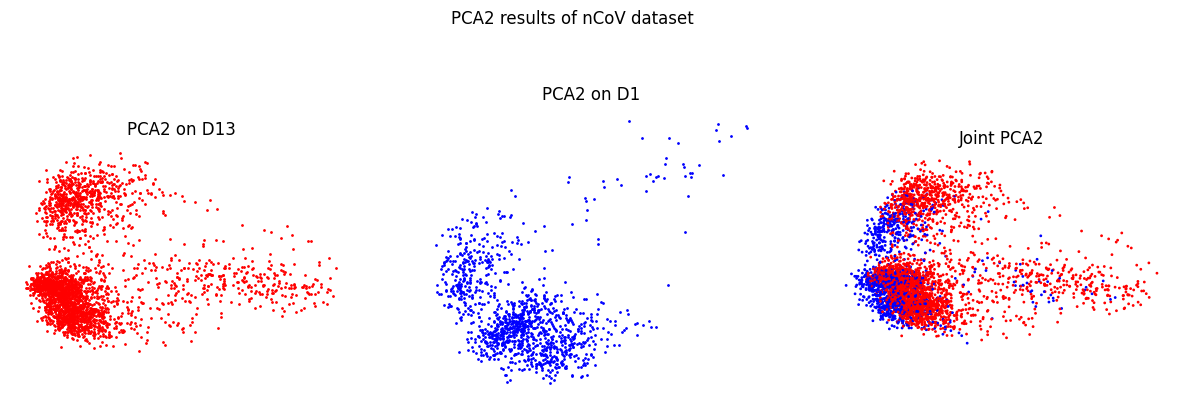

In [84]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].scatter(*pca1_50[:, :2].T, s=1, c="r")
ax[0].set_title("PCA2 on D13")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("PCA2 on D1")
ax[1].scatter(*pca2_50[:, :2].T, s=1, c="b")
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("Joint PCA2")

order = np.random.permutation(pcaj_50.shape[0])
colors = ["r"] * n0 + ["b"] * n1
ax[2].scatter(*pcaj_50[order, :2].T, s=1, c=np.array(colors)[order])
ax[2].set_aspect("equal")
ax[2].axis("off")

fig.suptitle(f"PCA2 results of {dataset} dataset")

fig.savefig(os.path.join(fig_path, f"{dataset}_pca2.png"), dpi=300)


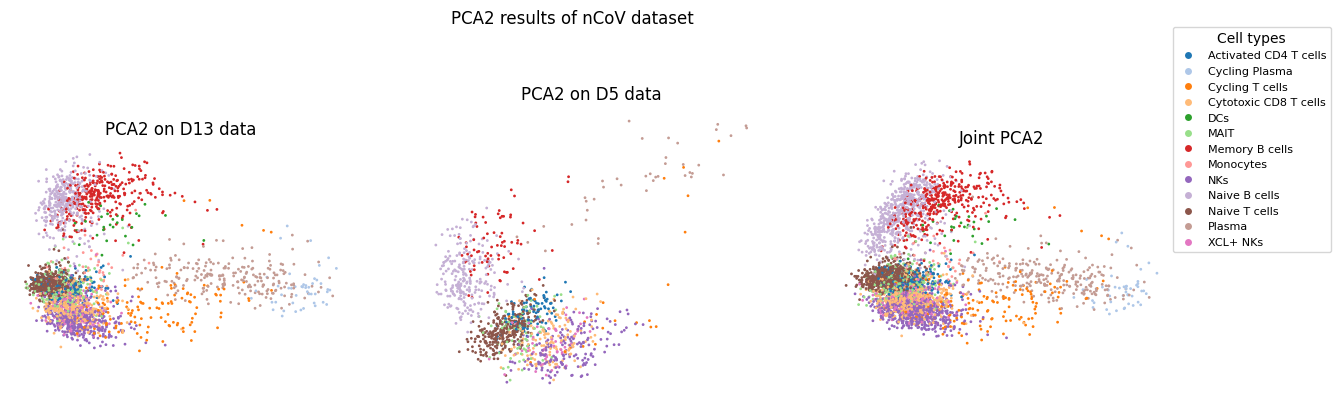

In [80]:
fig, ax = plt.subplots(1,3, figsize=(15,5))
ax[0].scatter(*pca1_50[:, :2].T, s=1, c=color1)
ax[0].set_title("PCA2 on D13 data")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("PCA2 on D5 data")
ax[1].scatter(*pca2_50[:, :2].T, s=1, c=color2)
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("Joint PCA2")

order = np.random.permutation(pcaj_50.shape[0])
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
ax[2].scatter(*pcaj_50[order, :2].T, s=1, c=colorj[order])
ax[2].set_aspect("equal")
ax[2].axis("off")

handles = [
    mlines.Line2D(
        [], [], linestyle="none", marker="o",
        markersize=5, markerfacecolor=cmap(i ),
        markeredgecolor="none", label=str(lbl)
    )
    for i, lbl in enumerate(unique_cell_types)
]

ax[2].legend(handles=handles, title="Cell types", loc=(1.0, 0.5), fontsize=8)


fig.suptitle(f"PCA2 results of {dataset} dataset")

fig.savefig(os.path.join(fig_path, f"{dataset}_by_type_pca2.png"), dpi=300)

In [81]:
tsne1 = TSNE(verbose=True).fit(pca1_50)
tsne2 = TSNE(verbose=True).fit(pca2_50)
tsnej = TSNE(verbose=True).fit(pcaj_50)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 1.07 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.08 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=236.58 for 250 iterations...
Iteration   50, KL divergence 3.6122, 50 iterations in 4.1044 sec
Iteration  100, KL divergence 3.6441, 50 iterations in 3.7847 sec
Iteration  150, KL divergence 3.6530, 50 iterations in 3.7523 sec
Iteration  200, KL divergence 3.6518, 50 iterations in 3.7515 sec
Iteration  250, KL divergence 3.6522, 50 iterations in 3.7333 sec
   --> Time elapsed: 19.13 seconds
===> Running optimization with exaggeration=1.00, lr=2839.00 for 500 ite

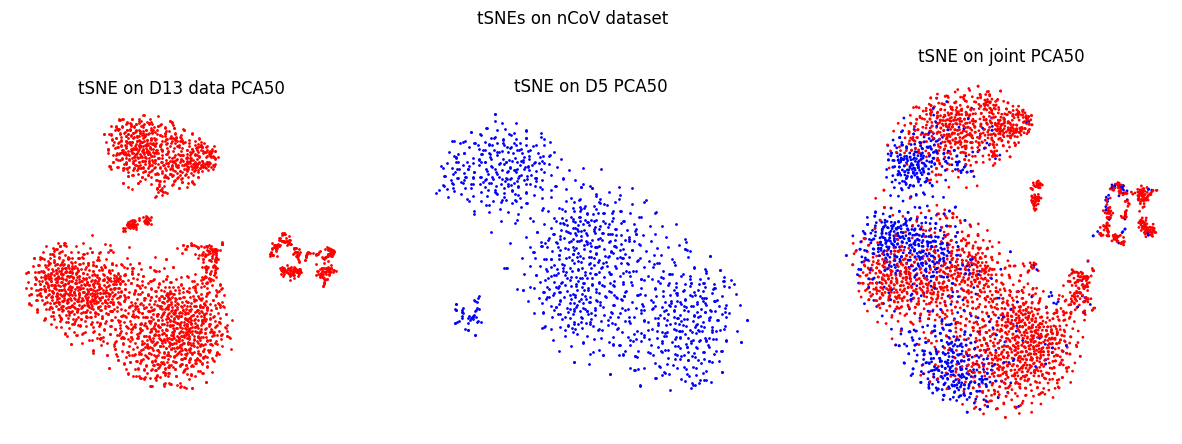

In [85]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].scatter(*tsne1.T, s=1, c="r")
ax[0].set_title("tSNE on D13 data PCA50")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("tSNE on D5 PCA50")
ax[1].scatter(*tsne2.T, s=1, c="b")
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("tSNE on joint PCA50")
colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(len(colors))
ax[2].scatter(*tsnej[order].T, s=1, c=np.array(colors)[order])
ax[2].set_aspect("equal")
ax[2].axis("off")
fig.suptitle(f"tSNEs on {dataset} dataset")

fig.savefig(os.path.join(fig_path, f"{dataset}_tsne.png"), dpi=300)

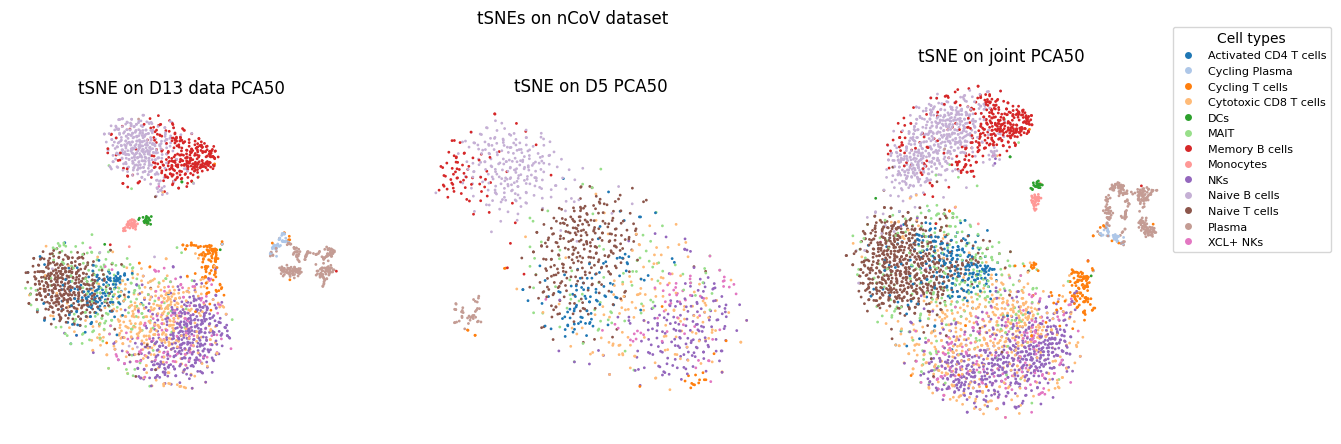

In [87]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].scatter(*tsne1.T, s=1, c=color1)
ax[0].set_title("tSNE on D13 data PCA50")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("tSNE on D5 PCA50")
ax[1].scatter(*tsne2.T, s=1, c=color2)
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("tSNE on joint PCA50")
colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(len(colors))
ax[2].scatter(*tsnej[order].T, s=1, c=colorj[order])
ax[2].set_aspect("equal")
ax[2].axis("off")
fig.suptitle(f"tSNEs on {dataset} dataset")

handles = [
    mlines.Line2D(
        [], [], linestyle="none", marker="o",
        markersize=5, markerfacecolor=cmap(i ),
        markeredgecolor="none", label=str(lbl)
    )
    for i, lbl in enumerate(unique_cell_types)
]

ax[2].legend(handles=handles, title="Cell types", loc=(1.0, 0.5), fontsize=8)

fig.savefig(os.path.join(fig_path, f"{dataset}_by_type_tsne.png"), dpi=300)

In [21]:
y1, y2 = np.load(os.path.join(res_path, "labels1.npy")), np.load(os.path.join(res_path, "labels2.npy"))

In [22]:
y1.max()

np.int64(12)

In [23]:
cmap = plt.get_cmap("tab20")

color1 = np.array([cmap(i) for i in y1])
color2 = np.array([cmap(i) for i in y2])
colorj = np.concatenate((color1, color2))

In [24]:
# diagonal variants

In [25]:
diag_tsne = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_1_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]
P1 = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_1_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["P_sparse"]

In [26]:
n0, n1 = P1.shape

In [13]:
P1.min(), P1.max()

(np.float64(1.6011794839399555e-07), np.float64(1.4672836465175603e-06))

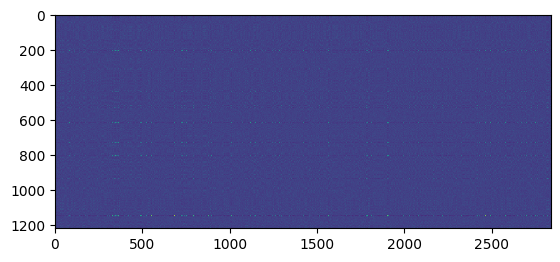

In [14]:
plt.imshow(P1.T, interpolation="none", vmin=0)

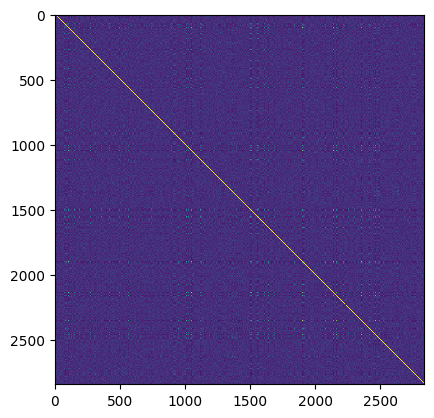

In [17]:
g = get_bipartite_graph(P1, diag=True).toarray()
#np.fill_diagonal(g, g.max())
g_plot = g[:n0,:n0].copy()
np.fill_diagonal(g_plot, g_plot.max())
plt.imshow(g_plot, interpolation="none")

In [24]:
diag_tsne.shape

(4060, 2)

In [25]:
colorj.shape

(4060, 4)

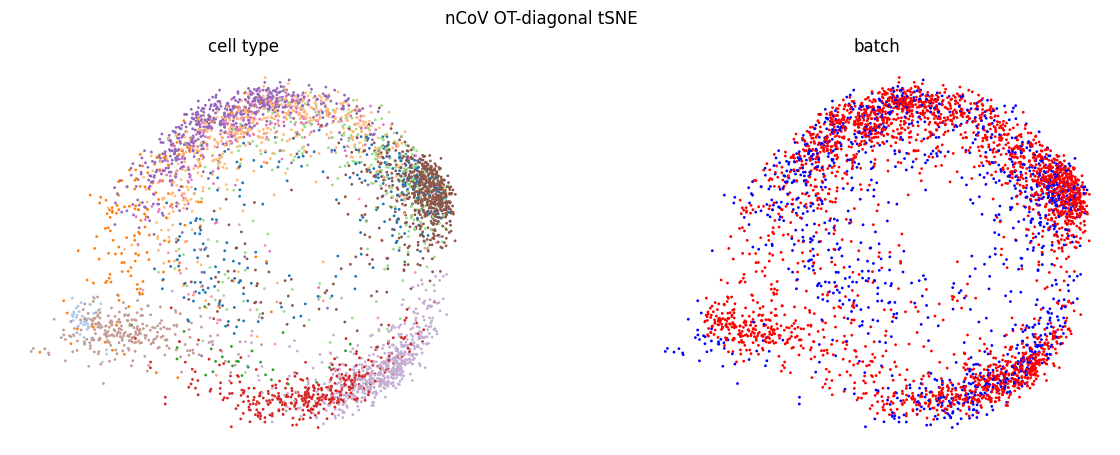

In [52]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(len(colorj))

ax[0].scatter(*diag_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*diag_tsne[order].T, s=1, c=np.array(colors)[order])
ax[1].set_title("batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

fig.suptitle(f"{dataset} OT-diagonal tSNE")

fig.savefig(os.path.join(fig_path, f"{dataset}_ot_diag_tsne_eps_1.png"), dpi=300)

In [42]:
g_single = g[:n0, :n0].copy()

g_single /= g_single.sum()



In [20]:
from openTSNE.affinity import Affinities
import scipy.sparse as sp

In [44]:
embd_dim = 2
seed = 0
init = np.random.randn(g_single.shape[0], embd_dim) / 10000

In [45]:
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=66,
                n_iter=133)
affinities = Affinities()
affinities.P = sp.csr_matrix(g_single)

embd_single = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=133,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=236.58 for 66 iterations...
Iteration   50, KL divergence -1.6864, 50 iterations in 5.2035 sec
   --> Time elapsed: 6.18 seconds
===> Running optimization with exaggeration=1.00, lr=2839.00 for 133 iterations...
Iteration   50, KL divergence 0.0037, 50 iterations in 6.3551 sec
Iteration  100, KL divergence 0.0035, 50 iterations in 5.6833 sec
   --> Time elapsed: 15.73 seconds


int64


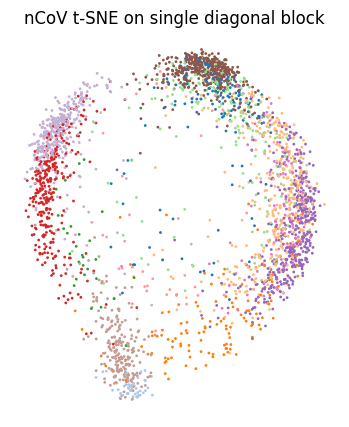

In [47]:
fig, ax = plt.subplots(1,1, figsize=(5,5))

order = np.random.permutation(n0)
print(order.dtype)

ax.scatter(*embd_single[order].T, s=1, c=colorj[order])
ax.set_title(f"{dataset} t-SNE on single diagonal block")
ax.set_aspect("equal")
ax.axis("off")
fig.savefig(os.path.join(fig_path, f"{dataset}_ot_diag_singleblock_tsne.png"), dpi=300)

In [57]:
no_diag_tsne = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_1_diag_False_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]

(np.float64(-0.5700464114435659),
 np.float64(0.5967382465245452),
 np.float64(-0.5791195732277747),
 np.float64(0.5979350853312247))

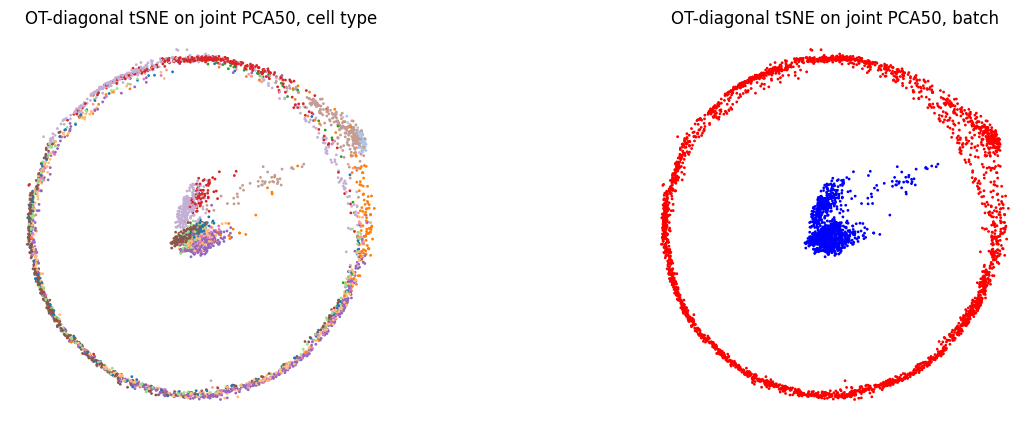

In [58]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

colors = ["r"] * X1_f.shape[0] + ["b"] * X2_f.shape[0]
order = np.random.permutation(len(colorj))

ax[0].scatter(*no_diag_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("OT-diagonal tSNE on joint PCA50, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*no_diag_tsne[order].T, s=1, c=np.array(colors)[order])
ax[1].set_title("OT-diagonal tSNE on joint PCA50, batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

fig.savefig(os.path.join(fig_path, f"{dataset}_ot_nodiag_tsne.png"), dpi=300)

In [29]:
diag_100_tsne = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_100_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["embd"]
P_100 = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_100_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")["P_sparse"]

In [30]:
P_100.min(), P_100.max()

(np.float64(1.8244197418976813e-94), np.float64(0.00035223356823511773))

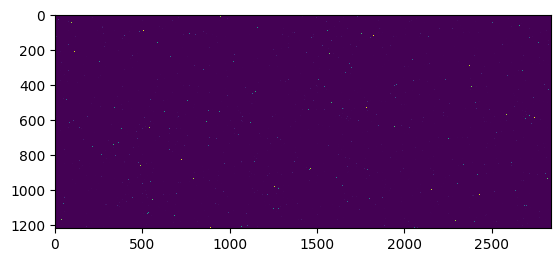

In [31]:
plt.imshow(P_100.T, interpolation="none" )

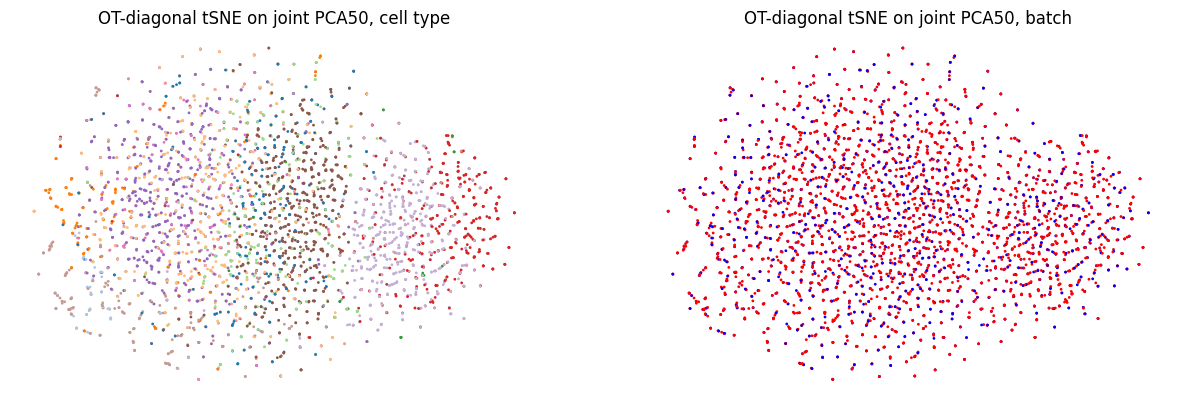

In [33]:
fig, ax = plt.subplots(1,2, figsize=(15,5))

colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(len(colorj))

ax[0].scatter(*diag_100_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("OT-diagonal tSNE on joint PCA50, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*diag_100_tsne[order].T, s=1, c=np.array(colors)[order])
ax[1].set_title("OT-diagonal tSNE on joint PCA50, batch")
ax[1].set_aspect("equal")
ax[1].axis("off")
fig.savefig(os.path.join(fig_path, f"{dataset}_ot_diag_tsne_eps_100.png"), dpi=300)


In [ ]:
## eps=10

In [34]:
diag_10_tsne = np.load(
    "/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_10_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")[
    "embd"]
P_10 = np.load("/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_10_diag_True_sparsify_None_norm_whole_dim_2_init_random_scale_10000_epochs_200_tsne.npz")[
    "P_sparse"]

In [35]:
P_10.min(), P_10.max()

(np.float64(9.250559040533082e-14), np.float64(0.00010647323322565166))

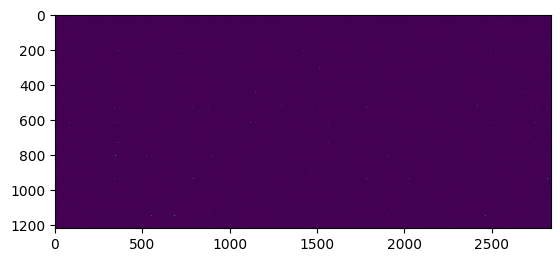

In [36]:
plt.imshow(P_10.T, interpolation="none")

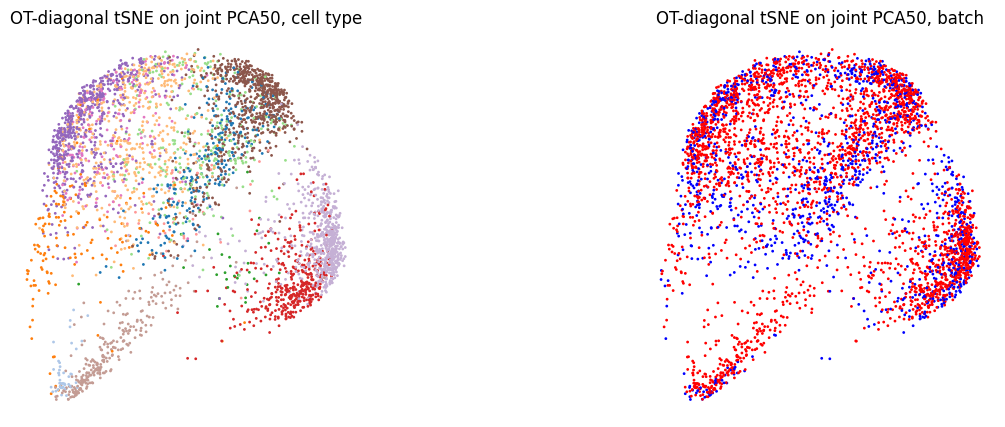

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(len(colorj))

ax[0].scatter(*diag_10_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("OT-diagonal tSNE on joint PCA50, cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*diag_10_tsne[order].T, s=1, c=np.array(colors)[order])
ax[1].set_title("OT-diagonal tSNE on joint PCA50, batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

fig.savefig(os.path.join(fig_path, f"{dataset}_ot_diag_tsne_eps_10.png"), dpi=300)


In [48]:
# sparsified eps=1

In [50]:
diag_1_sparse_tsne = np.load(
    "/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_1_diag_True_sparsify_None_norm_whole_sparsify_aff_True_dim_2_init_random_scale_10000_epochs_200_tsne.npz")[
    "embd"]

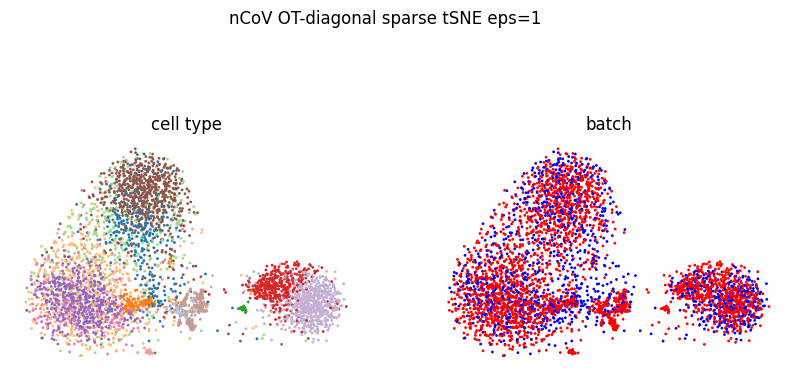

In [91]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(len(colorj))

ax[0].scatter(*diag_1_sparse_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*diag_1_sparse_tsne[order].T, s=1, c=np.array(colors)[order])
ax[1].set_title("batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

fig.suptitle(f"{dataset} OT-diagonal sparse tSNE eps=1")

fig.savefig(os.path.join(fig_path, f"{dataset}_ot_diag_sparse_tsne_eps_1.png"), dpi=300)

In [92]:
no_diag_1_sparse_tsne = np.load(
    "/gpfs01/berens/user/sdamrich/data/ne_aligned/nCoV/nCoV_seed_0_epstimes_1_diag_False_sparsify_None_norm_whole_sparsify_aff_True_dim_2_init_random_scale_10000_epochs_200_tsne.npz")[
    "embd"]

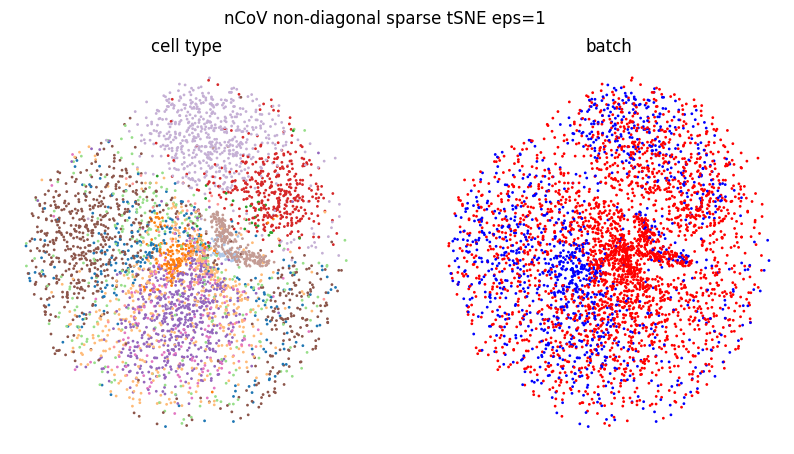

In [93]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(len(colorj))

ax[0].scatter(*no_diag_1_sparse_tsne[order].T, s=1, c=colorj[order])
ax[0].set_title("cell type")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*no_diag_1_sparse_tsne[order].T, s=1, c=np.array(colors)[order])
ax[1].set_title("batch")
ax[1].set_aspect("equal")
ax[1].axis("off")

fig.suptitle(f"{dataset} non-diagonal sparse tSNE eps=1")

fig.savefig(os.path.join(fig_path, f"{dataset}_non_diag_sparse_tsne_eps_1.png"), dpi=300)

In [94]:
# check plans

In [32]:
sorted_idx0 = np.argsort(y1)
sorted_idx1 = np.argsort(y2)
sorted_idx = np.concatenate((sorted_idx0, sorted_idx1 + n0))

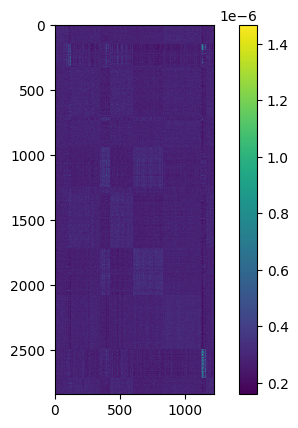

In [105]:
plt.imshow(P1[np.ix_(sorted_idx0, sorted_idx1)], interpolation="none")
plt.colorbar()

In [98]:
P1.shape

(2839, 1221)

In [99]:
len(y1)

2839

In [100]:
len(y2)

1221

In [102]:
P1.min()

np.float64(1.6011794839399555e-07)

In [103]:
P1.max()

np.float64(1.4672836465175603e-06)

In [28]:
g = get_bipartite_graph(P1, diag=True).toarray()

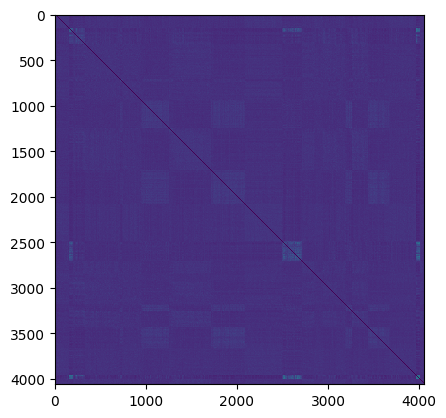

In [106]:
plt.imshow(g[np.ix_(sorted_idx, sorted_idx)], interpolation="none")

In [110]:
from ne_aligned_utils.utils import sparsify_affinities

ImportError: cannot import name 'sparsify_affinities' from 'ne_aligned_utils.utils' (/gpfs01/berens/user/sdamrich/mirrored_code/ne_aligned/src/ne_aligned_utils/utils.py)

In [30]:
g_sparse = sparsify_affinities(g,n0=n0, n1=n1, k=15)

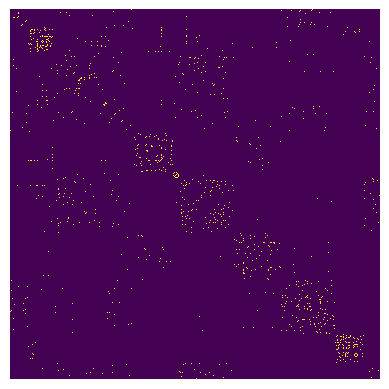

In [71]:
plt.imshow(g_sparse[np.ix_(sorted_idx0, sorted_idx0)], interpolation="none")
plt.axis("off")
plt.savefig(os.path.join(fig_path, f"{dataset}_sparsified_ot_affinity_upper_diag.png"), dpi=300)

In [39]:
embedder = TSNE(verbose=True, n_iter=1).fit(pca1_50)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, n_iter=1, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 0.99 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.08 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=236.58 for 250 iterations...
Iteration   50, KL divergence 3.6115, 50 iterations in 4.0862 sec
Iteration  100, KL divergence 3.6401, 50 iterations in 3.7393 sec
Iteration  150, KL divergence 3.6469, 50 iterations in 3.7137 sec
Iteration  200, KL divergence 3.6459, 50 iterations in 3.7319 sec
Iteration  250, KL divergence 3.6456, 50 iterations in 3.7469 sec
   --> Time elapsed: 19.02 seconds
===> Running optimization with exaggeration=1.00, lr=2839.00 f

In [53]:
tsne_affinities = embedder.affinities.P.toarray()
tsne_bin_aff = (tsne_affinities > 0).astype(float)

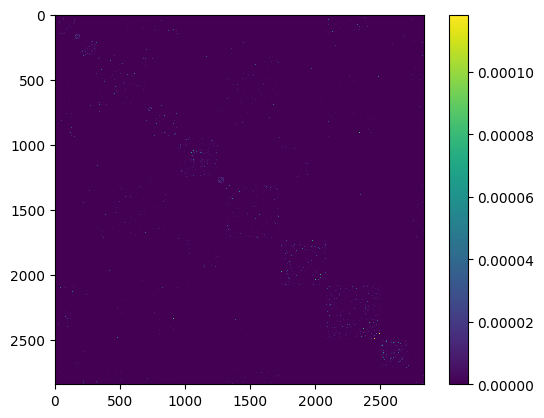

In [56]:
plt.imshow(tsne_affinities[np.ix_(sorted_idx0, sorted_idx0)], interpolation="none")
plt.colorbar()

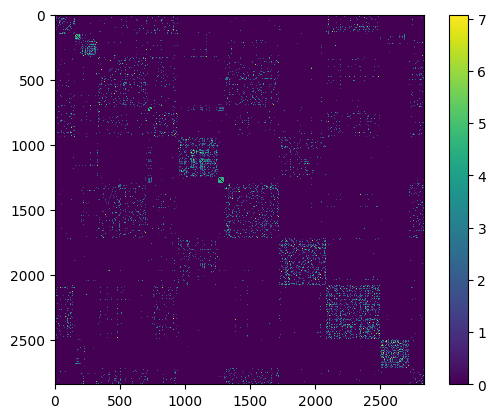

In [55]:
plt.imshow(np.log1p(10**7*tsne_affinities[np.ix_(sorted_idx0, sorted_idx0)]), interpolation="none")
plt.colorbar()


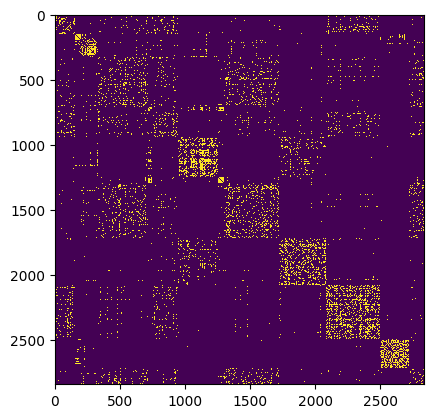

In [54]:
plt.imshow(tsne_bin_aff[np.ix_(sorted_idx0, sorted_idx0)], interpolation="none")


In [58]:
tsne_bin_aff.sum(1).min()

np.float64(90.0)

In [59]:
from openTSNE.affinity import Uniform

In [67]:
uni_aff = Uniform(pca1_50, k_neighbors=15, symmetrize="max").P.toarray()

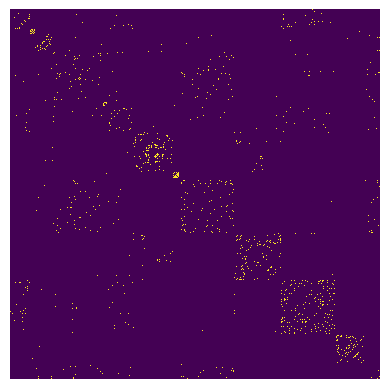

In [72]:
plt.imshow(uni_aff[np.ix_(sorted_idx0, sorted_idx0)], interpolation="none")
plt.axis("off")
plt.savefig(os.path.join(fig_path, f"{dataset}_uniform_kNN_affinity_upper_diag.png"), dpi=300)